In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that hand and JAX agree to ~1e-15
import matplotlib.pyplot as plt
import numpy as np

from _Part_a import LeakyReLU, Sigmoid, Identity, MSE
from optimizer import Adam
from neural_network import NeuralNetRegressor
from general_functions import Scaler, RungeData, FIG_DIR, runge
from linear_regression import ridge_theta, lasso_theta


from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold,  GridSearchCV
from sklearn.preprocessing import StandardScaler     

from matplotlib.patches import Rectangle
import seaborn as sea
from plot_colors import *
set_style()

In [2]:
"""Getting and splitting the data, scaling is done in the cv loop"""
data = RungeData()
X_train, X_test, y_train, y_test = data.split(data.nn_features())

epochs = 500
batch_size = 16
sizes = [50, 50, 1]          # chosen architecture from c

#same hyperparams as exercises w44
lambdas = [0.0, 1e-5, 1e-4, 1e-3, 1e-2]
gammas = [0.001, 0.003, 0.01, 0.03, 0.1]

#the same 5 folds for every model
cv = KFold(n_splits=5, shuffle=True, random_state=2026)    
k = cv.get_n_splits()

Sigmoid L2: lowest at lambda=0e+00, gamma=1e-03 (0.0177 +/- 0.0038); one standard error choice lambda=1e-04, gamma=1e-03 (0.0200 +/- 0.0035)
Sigmoid L1: lowest at lambda=1e-04, gamma=1e-01 (0.0174 +/- 0.0036); one standard error choice lambda=1e-04, gamma=1e-03 (0.0189 +/- 0.0036)


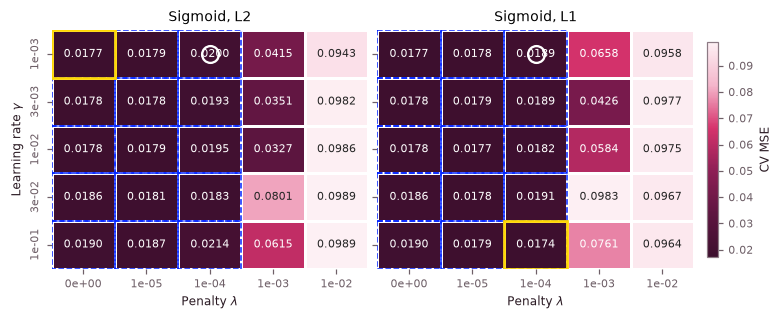

LeakyReLU L2: lowest at lambda=1e-03, gamma=1e-03 (0.0173 +/- 0.0039); one standard error choice lambda=1e-03, gamma=1e-03 (0.0173 +/- 0.0039)
LeakyReLU L1: lowest at lambda=1e-04, gamma=1e-03 (0.0173 +/- 0.0037); one standard error choice lambda=1e-03, gamma=1e-03 (0.0181 +/- 0.0038)


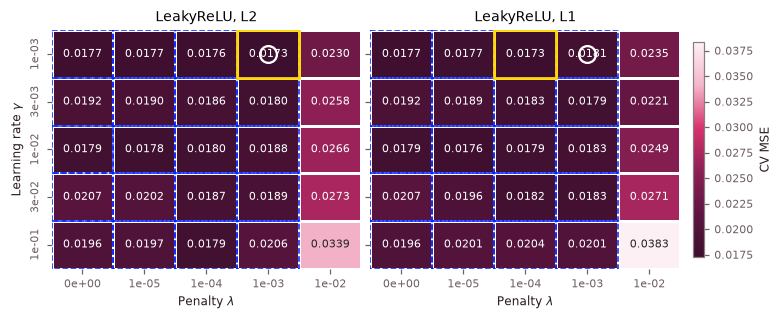

In [15]:
"""5-fold CV for all combinations of lambda and gamma for each activation
function and each norm (L1 and L2), based on exercises w44 code"""

act_funcs = {'Sigmoid': Sigmoid, 'LeakyReLU': LeakyReLU} #test for both act funcs
#grid for every combination of lrs and penalties
param_grid = {"neuralnetregressor__gamma": gammas, "neuralnetregressor__lmbd": lambdas}

shape = (len(gammas), len(lambdas))
results = {}

for act_name, act in act_funcs.items():
    #Ridge and Lasso penalties on network weights
    for reg in ['L2', 'L1']:
        #scale data in the fold to avoid leakage
        nn = make_pipeline(StandardScaler(),
                           NeuralNetRegressor(layer_output_sizes=sizes, activation_functions=[act, act, Identity],
                                              optimizer=Adam, penalty_type=reg, epochs=epochs,
                                              batch_size=batch_size, seed=2026))
        #train network for every hyperparam on every fold
        search = GridSearchCV(nn, param_grid, cv=cv, scoring='neg_mean_squared_error')
        search.fit(X_train, y_train)

        # save the mse and std from the training
        cv_mse = -search.cv_results_['mean_test_score'].reshape(shape)
        cv_se = search.cv_results_['std_test_score'].reshape(shape) / np.sqrt(k - 1)
        
        results[(act_name, reg)] = (search, cv_mse, cv_se)


"""Heatmap of the CV MSE, one heatmap per activation function with L2 and L1
The lowest MSE is marked in gold, the dashed boxes in blue show the MSEs within one
standard error of the lowest MSE, and the 1SE is marked with a circle. 
LLM Assisted"""
for act_name in act_funcs:
    fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), sharey=True, layout="constrained")

    mses = [results[(act_name, reg)][1] for reg in ['L2', 'L1']]
    vmin, vmax = np.nanmin(mses), np.nanmax(mses)

    for ax, reg in zip(axes, ['L2', 'L1']):
        search, cv_mse, cv_se = results[(act_name, reg)]

        i, j = np.unravel_index(np.nanargmin(cv_mse), cv_mse.shape)
        within = cv_mse <= cv_mse[i, j] + cv_se[i, j]
        cands = list(zip(*np.where(within)))
        i1, j1 = max(cands, key=lambda c: (lambdas[c[1]], -gammas[c[0]]))

        sea.heatmap(cv_mse, ax=ax, cmap=MSE_CMAP, vmin=vmin, vmax=vmax, cbar=False,
                    annot=True, fmt=".4f", annot_kws={"size": 7},
                    linewidths=0.8, linecolor="white",
                    xticklabels=[f"{l:.0e}" for l in lambdas],
                    yticklabels=[f"{g:.0e}" for g in gammas])

        for a, b in zip(*np.where(within)):
            ax.add_patch(Rectangle((b, a), 1, 1, fill=False, edgecolor="#0123FF", lw=1, ls="--"))
        ax.add_patch(Rectangle((j, i), 1, 1, fill=False, edgecolor="gold", lw=1.8))
        ax.plot(j1 + 0.5, i1 + 0.5, "o", mfc="none", mec="white", mew=1.5, ms=11)

        print(f"{act_name} {reg}: lowest at lambda={lambdas[j]:.0e}, gamma={gammas[i]:.0e} "
              f"({cv_mse[i, j]:.4f} +/- {cv_se[i, j]:.4f}); one standard error choice lambda={lambdas[j1]:.0e}, "
              f"gamma={gammas[i1]:.0e} ({cv_mse[i1, j1]:.4f} +/- {cv_se[i1, j1]:.4f})")

        ax.set_title(f"{act_name}, {reg}", fontsize=9)
        ax.set_xlabel(r"Penalty $\lambda$", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.grid(False)

    axes[0].set_ylabel(r"Learning rate $\gamma$", fontsize=8)
    axes[1].set_ylabel("")
    cbar = fig.colorbar(axes[0].collections[0], ax=axes, shrink=0.9, pad=0.02)
    cbar.set_label("CV MSE", fontsize=8)
    cbar.ax.tick_params(labelsize=7)

    plt.savefig(FIG_DIR / f"Part_d_heatmap_mses_{act_name}.pdf")
    plt.show()

In [6]:
"""Ridge and Lasso from project 1 (our linear_regression.py) with the best degree and lambdas from project 1,
fitted on the same training data and evaluated on the same test data as the network"""

#Best parameter from project 1
best_deg = 11               
ridge_lambda = 3.56e-5     
lasso_lambda = 7.28e-5      

#Get and scale data for the polynomial fit
X_polynom = data.polynomial_features(best_deg, intercept=False)
Xp_train, Xp_test, yp_train, yp_test = data.split(X_polynom)

scaler = Scaler().fit(Xp_train, yp_train)
Xp_train_s, yp_train_s = scaler.transform(Xp_train, yp_train)
Xp_test_s, yp_test_s = scaler.transform(Xp_test, yp_test)

#Derive the thetas for Ridge and Lasso
thetas = {'Ridge': np.asarray(ridge_theta(Xp_train_s, yp_train_s, ridge_lambda)),
          'Lasso': lasso_theta(Xp_train_s, yp_train_s, lasso_lambda, 10000, 1e-8)}

#Find the test MSE from regular ridge and lasso regression using params from p1 
poly_results = {}
for name, lam in [('Ridge', ridge_lambda), ('Lasso', lasso_lambda)]:
    test_mses = MSE()(Xp_test_s @ thetas[name], yp_test_s)
    poly_results[name] = (lam, test_mses)
    print(f'{name} (degree {best_deg}, lambda = {lam:.0e}): test MSE = {test_mses:.4f}')

Ridge (degree 11, lambda = 4e-05): test MSE = 0.0219
Lasso (degree 11, lambda = 7e-05): test MSE = 0.0220


In [7]:
"""Comparison on the test set. The networks use the one-standard-error choice
of lambda and gamma from the heatmaps, retrained on all training data"""
from sklearn.base import clone

def test_mse(model):
    """Calculate the MSE on the final test set"""
    return np.mean((model.predict(X_test) - y_test) ** 2)

# the one s-e hyperparams read off from the heatmaps
one_se_params = {('Sigmoid', 'L2'):   (1e-4, 0.001),
                 ('Sigmoid', 'L1'):   (1e-4, 0.001),
                 ('LeakyReLU', 'L2'): (1e-3, 0.001),
                 ('LeakyReLU', 'L1'): (1e-3, 0.001)}

one_se_models = {}

#LLM Assisted
print(f"{'Model':20s} {'lambda':>8s} {'gamma':>8s} {'CV MSE':>18s} {'Test MSE':>10s}")

for (act_name, reg), (lam, gam) in one_se_params.items():
    search, cv_mse, cv_se = results[(act_name, reg)]

    # same pipeline as in the grid search, with the chosen lambda and gamma, trained on all training data
    model = clone(search.best_estimator_).set_params(neuralnetregressor__lmbd=lam,
                                                     neuralnetregressor__gamma=gam)
    model.fit(X_train, y_train)
    one_se_models[(act_name, reg)] = model

    # CV MSE of the chosen cell (rows = gamma, columns = lambda)
    i, j = gammas.index(gam), lambdas.index(lam)
    print(f"{'NN ' + act_name + ' ' + reg:20s} {lam:8.0e} {gam:8.0e} "
          f"{cv_mse[i, j]:9.4f} +/- {cv_se[i, j]:.4f} {test_mse(model):10.4f}")

# Ridge and Lasso with the degree and lambdas from project 1, on the same test points
for name, (lam, test) in poly_results.items():
    print(f"{name + f' (degree {best_deg})':20s} {lam:8.1e} {'-':>8s} {'project 1':>18s} {test:10.4f}")

Model                  lambda    gamma             CV MSE   Test MSE
NN Sigmoid L2           1e-04    1e-03    0.0200 +/- 0.0035     0.0163
NN Sigmoid L1           1e-04    1e-03    0.0189 +/- 0.0036     0.0147
NN LeakyReLU L2         1e-03    1e-03    0.0173 +/- 0.0039     0.0151
NN LeakyReLU L1         1e-03    1e-03    0.0181 +/- 0.0038     0.0156
Ridge (degree 11)     3.6e-05        -          project 1     0.0219
Lasso (degree 11)     7.3e-05        -          project 1     0.0220


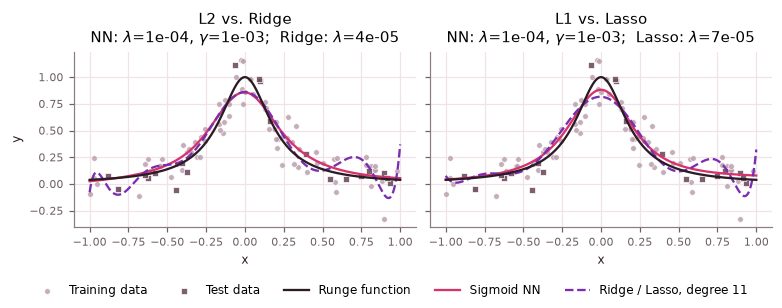

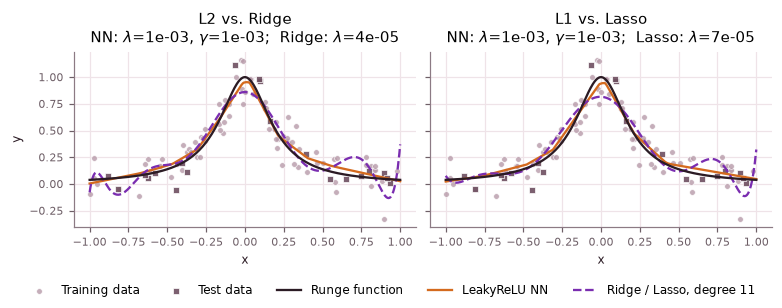

In [ ]:
"""The best network for each activation and norm (refitted on all training data by GridSearchCV),
compared with Ridge (L2) and Lasso (L1) from project 1, LLM Assisted"""
x_grid = np.linspace(-1, 1, 400).reshape(-1, 1)
X_grid_s = np.asarray(scaler.transform_X(RungeData.design_matrix(x_grid.ravel(), best_deg, intercept=False)))
poly_name = {'L2': 'Ridge', 'L1': 'Lasso'}

for act_name in act_funcs:
    fig, axes = plt.subplots(1, 2, figsize=(7, 2.7), sharex=True, sharey=True, layout="constrained")

    for ax, reg in zip(axes, ['L2', 'L1']):
        name = poly_name[reg]
        lam_nn, gam_nn = one_se_params[(act_name, reg)]
        y_nn = one_se_models[(act_name, reg)].predict(x_grid)
        y_poly = scaler.inverse_transform_y(X_grid_s @ thetas[name])

        plot_data_and_truth(ax, x_grid, runge(x_grid), X_train, y_train, X_test, y_test)
        ax.plot(x_grid, y_nn, color=ACTIVATION_COLORS[act_name], label=f"{act_name} NN")
        ax.plot(x_grid, y_poly, "--", color=COLORS["ols"], label=f"Ridge / Lasso, degree {best_deg}")

        # hyperparameters in the title instead of the legend
        ax.set_title(f"{reg} vs. {name}\n"
                     rf"NN: $\lambda$={lam_nn:.0e}, $\gamma$={gam_nn:.0e};  "
                     rf"{name}: $\lambda$={poly_results[name][0]:.0e}", fontsize=10)
        ax.set_xlabel("x", fontsize=8)
        ax.tick_params(labelsize=7)

    axes[0].set_ylabel("y", fontsize=8)

    # one shared legend below both panels, nothing inside the axes
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=len(handles), fontsize=8)

    plt.savefig(FIG_DIR / f"Part_d_nn_vs_rnl_from_p1_{act_name}.pdf")
    plt.show()